# Dataset Pipline
 goal: Prepare historical student data for the Academic Early Warning System.

  ** Outlines: **

 * Clean dataset
 * Engineered features
 * Train/Validation/Test splits
 * Leakage validation report

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
# step 2: Load Dataset and transform to Dataframe structure 

df = pd.read_csv("synthetic_student_data.csv")

print(df.shape)
df.head()


(212, 14)


,Anonymous Student Identifier,Program,Academic Term,Course Attempts,Credits Attempted,Credits Completed,Course Outcomes,Semester GPA,Cumulative GPA,Withdrawals,Repeated Courses,Progression Status,Attendance,Early Assessment Results
0,STU_0001,Psychology,2025-Fall,5,15,15,"CRSE-121: 2.0, CRSE-352: 2.4, CRSE-335: 1.6, C...",1.85,1.85,0,0,Academic Warning,NaN,Fail
1,STU_0002,Psychology,2025-Fall,4,12,12,"CRSE-428: 2.0, CRSE-266: 2.4, CRSE-373: 2.6, C...",2.43,2.43,0,0,Good Standing,NaN,NaN
2,STU_0002,Psychology,2026-Spring,4,12,12,"CRSE-134: 2.2, CRSE-305: 1.4, CRSE-180: 2.7, C...",2.00,2.22,0,0,Good Standing,NaN,NaN
3,STU_0002,Psychology,2026-Fall,4,12,12,"CRSE-370: 2.4, CRSE-314: 1.8, CRSE-351: 2.4, C...",2.41,2.28,0,0,Good Standing,95%,NaN
4,STU_0003,Nursing,2025-Fall,5,15,15,"CRSE-360: 1.6, CRSE-330: 2.3, CRSE-140: 2.5, C...",2.34,2.34,0,0,Good Standing,NaN,NaN


In [4]:
# Initial Data Inspection Statistical Summary
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Anonymous Student Identifier  212 non-null    object 
 1   Program                       212 non-null    object 
 2   Academic Term                 212 non-null    object 
 3   Course Attempts               212 non-null    int64  
 4   Credits Attempted             212 non-null    int64  
 5   Credits Completed             212 non-null    int64  
 6   Course Outcomes               212 non-null    object 
 7   Semester GPA                  212 non-null    float64
 8   Cumulative GPA                212 non-null    float64
 9   Withdrawals                   212 non-null    int64  
 10  Repeated Courses              212 non-null    int64  
 11  Progression Status            212 non-null    object 
 12  Attendance                    102 non-null    object 
 13  Early

,Anonymous Student Identifier,Program,Academic Term,Course Attempts,Credits Attempted,Credits Completed,Course Outcomes,Semester GPA,Cumulative GPA,Withdrawals,Repeated Courses,Progression Status,Attendance,Early Assessment Results
count,212,212,212,212.000000,212.000000,212.000000,212,212.000000,212.000000,212.000000,212.000000,212,102,82
unique,100,5,3,NaN,NaN,NaN,212,NaN,NaN,NaN,NaN,3,27,3
top,STU_0002,Business Administration,2025-Fall,NaN,NaN,NaN,"CRSE-121: 2.0, CRSE-352: 2.4, CRSE-335: 1.6, C...",NaN,NaN,NaN,NaN,Good Standing,100%,Pass
freq,3,55,100,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,182,22,45
mean,NaN,NaN,NaN,3.962264,11.886792,11.292453,NaN,2.741981,2.740802,0.198113,0.094340,NaN,NaN,NaN
std,NaN,NaN,NaN,0.853479,2.560438,2.863289,NaN,0.744768,0.642960,0.494899,0.292992,NaN,NaN,NaN
min,NaN,NaN,NaN,3.000000,9.000000,3.000000,NaN,0.960000,1.100000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,3.000000,9.000000,9.000000,NaN,2.170000,2.280000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,4.000000,12.000000,12.000000,NaN,2.750000,2.780000,0.000000,0.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,5.000000,15.000000,15.000000,NaN,3.360000,3.232500,0.000000,0.000000,NaN,NaN,NaN


In [6]:
# Data Quality Assessment Percentage of missing values:

missing_sum_val = df.isnull().sum()
print(f" Sum of Missed values: {missing_sum_val}")

missing_sum_val.sort_values(ascending=False)

missing_percentage = (df.isnull().mean() * 100).round(2)
print(f"Percentage of missing values: {missing_percentage}")

print(missing_percentage.sort_values(ascending=False))



 Sum of Missed values: Anonymous Student Identifier      0
Program                           0
Academic Term                     0
Course Attempts                   0
Credits Attempted                 0
Credits Completed                 0
Course Outcomes                   0
Semester GPA                      0
Cumulative GPA                    0
Withdrawals                       0
Repeated Courses                  0
Progression Status                0
Attendance                      110
Early Assessment Results        130
dtype: int64
Percentage of missing values: Anonymous Student Identifier     0.00
Program                          0.00
Academic Term                    0.00
Course Attempts                  0.00
Credits Attempted                0.00
Credits Completed                0.00
Course Outcomes                  0.00
Semester GPA                     0.00
Cumulative GPA                   0.00
Withdrawals                      0.00
Repeated Courses                 0.00
Progression 

In [36]:
# Remove Duplicate Records Handle Missing Values 

df = df.drop_duplicates().copy()
print("Sum of Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# Fill missing numeric values with each column's median
numerical_cols = df.select_dtypes(include="number").columns
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after numeric imputation:")
print(df[numerical_cols].isna().sum())

# Keep missing Early Assessment Results unchanged; it is categorical.

# Fill missing numeric values with their medians
numerical_cols2 = [
   "Semester GPA",
   "Cumulative GPA",
   "Credits Completed",
   "Attendance",
]
for col in numerical_cols2:
    # Remove duplicate records
   numerical_cols2 = ["Semester GPA", "Cumulative GPA", "Credits Completed"]

df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())
Avg_attendance = df["Attendance"].mean()
print(f"Average of attendance = {Avg_attendance}")

Sum of Duplicates: 0
Missing values after numeric imputation:
Course Attempts      0
Credits Attempted    0
Credits Completed    0
Semester GPA         0
Cumulative GPA       0
Withdrawals          0
Repeated Courses     0
Attendance           0
dtype: int64
Average of attendance = 92.03301886792453


In [44]:
# Categorical Columns
categorical_cols = [
"program","Academic Term"
]
# Fill with most frequent value:
for col in categorical_cols:
    # Categorical columns present in df
    categorical_cols = ["Program","Academic Term"]

    for col in categorical_cols:
        if df[col].notna().any():
            df[col] = df[col].fillna(df[col].mode().iloc[0])
# Verify Missing Values Removed --> Expected output: All columns = 0 missing values
print(df.isnull().sum())
df[col] = df[col].fillna(df[col].mode(dropna=True).iloc[0])



Anonymous Student Identifier      0
Program                           0
Academic Term                     0
Course Attempts                   0
Credits Attempted                 0
Credits Completed                 0
Course Outcomes                   0
Semester GPA                      0
Cumulative GPA                    0
Withdrawals                       0
Repeated Courses                  0
Progression Status                0
Attendance                        0
Early Assessment Results        130
dtype: int64


In [50]:
# Basic Data Validation

print( df[
(df["Semester GPA"] >= 0)
& (df["Semester GPA"] <= 5)
])
print( df[
(df["Cumulative GPA"] >= 0)
& (df["Cumulative GPA"] <= 5)
])
print(df[
(df["Attendance"] >= 0)
& (df["Attendance"] <= 100)
])
# Dataset Summary
print("Final Shape:", df.shape)

print("Remaining Missing Values:",
      df.isnull().sum().sum())

    Anonymous Student Identifier                 Program Academic Term  \
0                       STU_0001              Psychology     2025-Fall   
1                       STU_0002              Psychology     2025-Fall   
2                       STU_0002              Psychology   2026-Spring   
3                       STU_0002              Psychology     2026-Fall   
4                       STU_0003                 Nursing     2025-Fall   
..                           ...                     ...           ...   
207                     STU_0098  Mechanical Engineering     2025-Fall   
208                     STU_0099              Psychology     2025-Fall   
209                     STU_0100  Mechanical Engineering     2025-Fall   
210                     STU_0100  Mechanical Engineering   2026-Spring   
211                     STU_0100  Mechanical Engineering     2026-Fall   

     Course Attempts  Credits Attempted  Credits Completed  \
0                  5                 15          

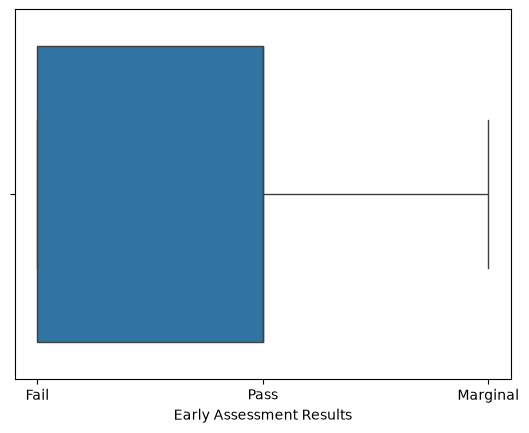

In [61]:
# Outlier Detection
sns.boxplot(
x=df["Early Assessment Results"]

)
plt.show()

Q1 = df["Semester GPA"].quantile(0.25)
Q3 = df["Cumulative GPA"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [71]:
# Define Target Variable ** GPA Risk Flag **

# Students are considered "at risk" when GPA is below 2.0.

df["academic_risk"] = (
df["Semester GPA"] < 2.0
).astype(int)
# Check class balance:

print(
    "Proportion by academic term, program, and risk status:"
)
print(
    df[["Academic Term", "Program", "academic_risk"]]
    .value_counts(normalize=True)
)

Proportion by academic term, program, and risk status:
Academic Term  Program                  academic_risk
2025-Fall      Mechanical Engineering   0                0.089623
               Business Administration  0                0.084906
2026-Spring    Mechanical Engineering   0                0.084906
2025-Fall      Computer Science         0                0.080189
2026-Spring    Business Administration  0                0.070755
2026-Fall      Business Administration  0                0.061321
2026-Spring    Nursing                  0                0.056604
2025-Fall      Psychology               0                0.056604
               Nursing                  0                0.056604
2026-Fall      Mechanical Engineering   0                0.047170
2026-Spring    Computer Science         0                0.047170
               Psychology               0                0.042453
2025-Fall      Business Administration  1                0.033019
2026-Fall      Nursing           

# Feature Engineering

  * Credit Completion Ratio
  * Repeated Courses Indicator
  * Withdrawal Indicator

## Leakage Check

  ** Create a section explaining that future information cannot be used.**
   *Forbidden features:*

In [181]:
Credit_Completion = (((df["Course Attempts"].astype(int)+df["Credits Attempted"].astype(int))/df["Credits Completed"]) * 100)
print(f"Credit Completion Ratio: {Credit_Completion}\n")

Featured_eng = df[
    [
        "credit_completion_ratio",
        "has_repeated_courses",
        "has_withdrawals",
    ]
].copy()

print("Count of Withdrawals by Academic Term and Withdrawals:\n")
print(pd.crosstab(df["Academic Term"], df["has_withdrawals"]))
# Keep the original row-level course outcomes; do not assign value_counts() back to this column.

df["has_repeated_courses"] = (df["Repeated Courses"] > 0).astype(int)
# Credit completion percentage; avoid division by zero
attempted = df["Credits Attempted"].replace(0, np.nan)
df["credits Completed"] = (
df["Credits Completed"].div(Credit_Completion).mul(100).fillna(0)
)
df["has_withdrawals"] = (df["Withdrawals"] > 0).astype(int)


Credit Completion Ratio: 0      106.666667
1      108.333333
2      108.333333
3      108.333333
4      106.666667
          ...    
207    108.333333
208    106.666667
209    106.666667
210    106.666667
211    111.111111
Length: 212, dtype: float64

Count of Withdrawals by Academic Term and Withdrawals:

has_withdrawals   0   1
Academic Term          
2025-Fall        87  13
2026-Fall        34   7
2026-Spring      58  13


In [182]:
# Save the cleaned dataset in new Cleaned_synthetic_stu_Data.csv 
df.to_csv(
    "Cleaned_synthetic_stu_Data.csv",
    index=False
)

print("Clean dataset Successfully saved!")

Clean dataset Successfully saved!
